In [1]:
import xcs_code_stockpile as xcs
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import medfilt

In [2]:
proposal_number = 101927227  # noqa
run = 67  # noqa

In [3]:
h5 = xcs.load_smalldata(run, proposal_number)
h5dict = xcs.H5Dictionary(
    stack='/jungfrau1M/ROI_area',
    i0=lambda h5: h5['diodeGon/channels'][..., 0],
    laser_on='evr/code_41',
    delay='scan/awg_delay_ns_delay',
    measured_voltage='ai/ch04'
)

In [4]:
metadata = xcs.create_metadata(h5, run, h5dict, roi=None)
valid = xcs.sensible_filter(metadata, 0.5, 99.5, 0.5, 99.5)

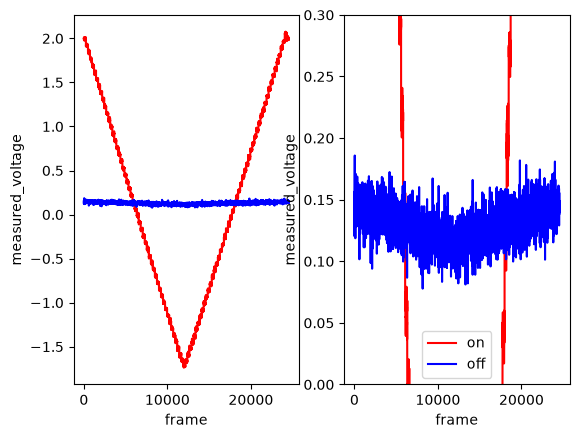

In [5]:
on_meta = metadata[metadata['laser_on']]
off_meta = metadata[~metadata['laser_on']]
fig, axs = plt.subplots(1, 2)
for ax in axs:
    ax.plot(on_meta['measured_voltage'], label='on', color='red')
    ax.plot(off_meta['measured_voltage'], label='off', color='blue')
    ax.set_xlabel('frame')
    ax.set_ylabel('measured_voltage')
axs[1].set_ylim(bottom=0.0, top=0.3)
plt.legend()
plt.show()

In [6]:
rois = [
    (slice(50,100), slice(150,220)), # whole ROI, bto and ctr and diffuse
    (slice(68, 78), slice(185, 195)), # ctr peak dominated
    (slice(68, 78), slice(165, 175)), # bto peak (clipped slightly)
    (slice(50,65), slice(185,195)), #diffuse area above the ctr
    (slice(50,65), slice(173,183)), # estimated satellite region
    (slice(50,100), slice(50,100)) # area far from peaks
]

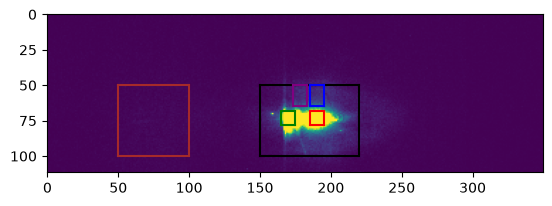

In [7]:
xcs.plot_detector_image(h5, h5dict, samplerate=100)
roi_colors = ['black', 'red', 'green', 'blue', 'purple', 'brown']
for i, roi in enumerate(rois):
    plt.plot([roi[1].start, roi[1].stop], [roi[0].start, roi[0].start], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].stop], [roi[0].stop, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].start, roi[1].start], [roi[0].start, roi[0].stop], color=roi_colors[i])
    plt.plot([roi[1].stop, roi[1].stop], [roi[0].start, roi[0].stop], color=roi_colors[i])

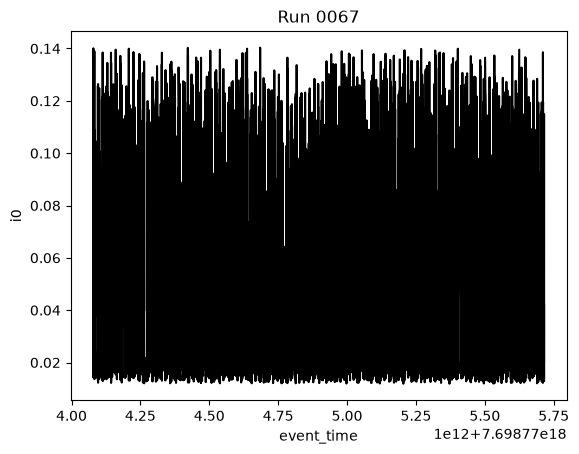

In [8]:
xcs.plot_i0_vs_time(metadata, valid).show()

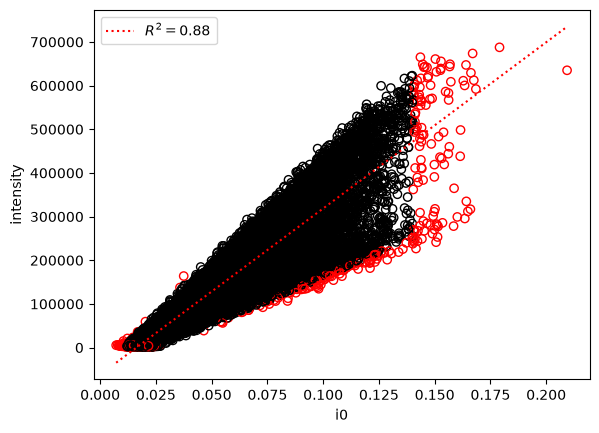

In [9]:
xcs.plot_intensity_vs_i0(metadata, valid).show()

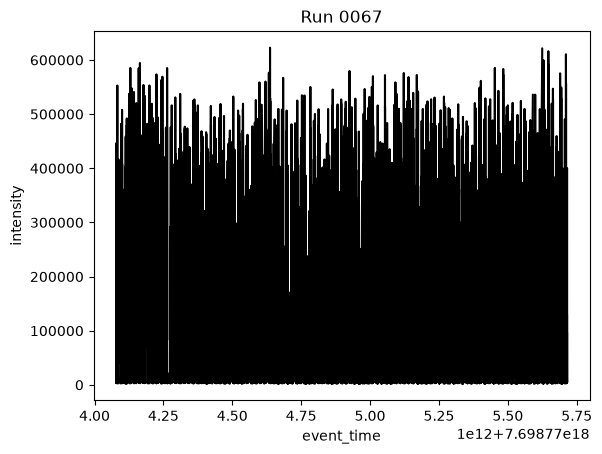

In [10]:
xcs.plot_intensity_vs_time(metadata, valid).show()

In [11]:
delays = h5[h5dict.delay][...]
diff = np.diff(delays)
u_diffs, counts = np.unique(diff, return_counts=True)
typical_dt = u_diffs[u_diffs > 0][np.argmax(counts[u_diffs > 0])]
print(f'{typical_dt=:0.2f}')

typical_dt=1000.00


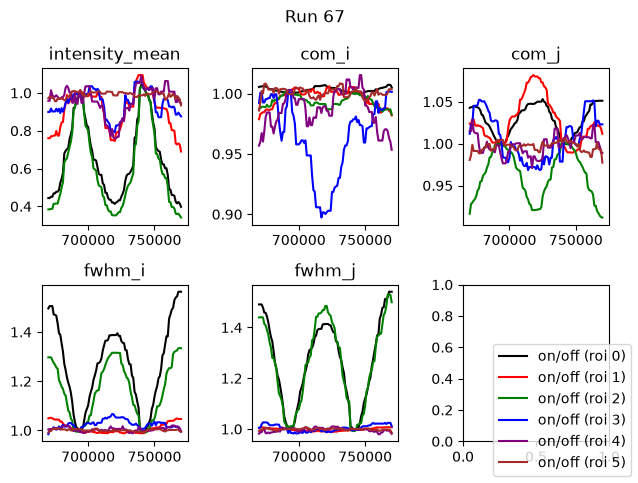

In [12]:

fig, axd = plt.subplot_mosaic([['intensity_mean', 'com_i', 'com_j'], ['fwhm_i', 'fwhm_j', '_skip']])
for i, (tag, ax) in enumerate(axd.items()):
    if tag == '_skip':
        continue
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, typical_dt, roi=roi)
        label = f'on/off (roi {j})' if i == 0 else None
        ax.plot(trxrd.index, medfilt(trxrd[f'on_{tag}']/trxrd[f'off_{tag}'], 5), color=color, linestyle='-', label=label)
    ax.set_title(tag)
fig.legend(loc='lower right')
fig.suptitle(f'Run {run}')
fig.tight_layout()
plt.show()

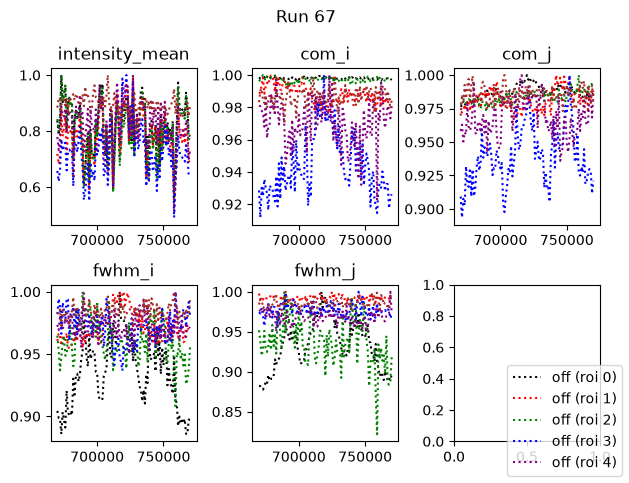

In [13]:


def normalize(a):
    return a / np.amax(a)


fig, axd = plt.subplot_mosaic([['intensity_mean', 'com_i', 'com_j'], ['fwhm_i', 'fwhm_j', '_skip']])
for i, (tag, ax) in enumerate(axd.items()):
    if tag == '_skip':
        continue
    for j, (roi, color) in enumerate(zip(rois, roi_colors)):
        trxrd = xcs.calc_trxrd_stats(h5, h5dict, metadata, valid, typical_dt, roi=roi)
        label = f'off (roi {j})' if j == i else None
        ax.plot(trxrd.index, normalize(trxrd[f'off_{tag}']), color=color, linestyle=':', label=label)
    ax.set_title(tag)
fig.legend(loc='lower right')
fig.suptitle(f'Run {run}')
fig.tight_layout()
plt.show()